## Parameter Variation Plots

In [1]:
# %%
from pathlib import Path
 
# Base folder holding FONTANKA's per-run output folders:
#   {fontanka_base}/simulation_results_{resolution}_{window_size}/FONTANKA_{hic_stem}.{resolution}.predicted.fountains.tsv
fontanka_base = Path("/nfs/turbo/umms-minjilab/sionkim/fontanka")
 
# Hi-C files (order MUST stay aligned with jet_loc_files below)
hic_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/out_fast_bounded_jets/r2.14/test1b_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_fast_unbounded_jets/r2.14/test1a_s-23-fast_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_unbounded_jets/r2.14/chromsim1-fast-unbounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_bounded_jets/r2.14/chromsim1-fast-bounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_slow_unbounded_jets/r2.14/test1a_s-23-slow_hic_003.hic",  # smaller window size / highest resolution possible
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/out_fast_bounded_jets/r2.14/test1c_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/out_fast_bounded_jets/r2.14/test1cii_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1e_s-23/out_tads/r2.14/test1e_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1eii_s-23/out_tads/r2.14/test1eii_s-23_hic_003.hic",
]
 
# True jet locations (None = TADs, no true jets)
jet_loc_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/narrow_loading_50.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-unbounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-bounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/diffuse_loading_10000.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/loading.csv",
    None,  # TADs
    None,  # TADs
]
 
# Defaults — held constant when the other parameter is swept
DEFAULT_RESOLUTION  = 25000
DEFAULT_WINDOW_SIZE = int(500e3) # 500 kb
 
# Swept values
RESOLUTIONS  = [10000, 25000, 50000, 100000]
WINDOW_SIZES = [100000, 500000, 1000000, 2000000, 3000000]
 
# FONTANKA's three thresholding modes (each pooled / plotted separately)
THRESH_MODES = ["unthresholded", "thresholded", "thresholded_weak"]
 
chrom = "chrS"
 
score_col = "f1"

In [2]:
# %%
import sys
sys.path.append('..')
import pybedtools
from utils.plotting import genomic_labels
# NOTE: FONTANKA does not need func_pileup.generate_bed_3 — predictions already give a
# main-diagonal "root", which we expand to start/end ourselves below.
 
def precision_recall_f1(tp, fp, fn):
    if tp == 0 and fp == 0 and fn == 0:
        return 1.0, 1.0, 1.0
 
    precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 1.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0.0)
    return precision, recall, f1
 
def find_intersections(df_pred_in, df_true_in, leniency):
    """
    The df_pred must have the following columns ['chrom', 'start', 'end', 'unique_id', 'root']
 
    The df_true is assumed to be the loading file given to the 3DPolyS-LE simulation,
    which has columns ['name', 'position', 'length', 'factor']. The only necessary column here is
    the 'position'
    """
    if df_pred_in.empty:
        # No predictions provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=0, fn=len(df_true_in) if df_true_in is not None else 0)
        result_dict = {
            "tp": 0,
            "fp": 0,
            "fn": len(df_true_in) if df_true_in is not None else 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": 0
        }
        return pd.DataFrame(), result_dict
 
    if df_true_in is None:
        # No true data provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred_in), fn=0)
        result_dict = {
            "tp": 0,
            "fp": len(df_pred_in),
            "fn": 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred_in)
        }
        return pd.DataFrame(), result_dict
 
    df_pred = df_pred_in.copy()
    df_true = df_true_in.copy()
 
    # Need to map from genomic coordinates to bin coordinates, which appears to
    # differ by resolution and factor 2
    df_true["position"] /= 2
    df_true["position"] = df_true["position"].astype(int)
 
    df_pred_bed = df_pred[["chrom", "start", "end", "unique_id", "root"]].copy()
 
    chrom = df_pred["chrom"].iloc[0]
    df_true_bed = df_true.assign(
        chrom=chrom,
        start=lambda d: np.clip(d["position"] - int(leniency), 0, None),
        end=lambda d: d["position"] + int(leniency) + 1,
    )[["chrom", "start", "end", "name", "position"]]
 
    pred_bed = pybedtools.BedTool.from_dataframe(df_pred_bed)
    true_bed = pybedtools.BedTool.from_dataframe(df_true_bed)
 
    hits = pred_bed.intersect(true_bed, wa=True, wb=True)
 
    intersections = hits.to_dataframe(names=[
        "chrom", "pred_start", "pred_end", "unique_id", "pred_root",
        "true_chrom", "true_start", "true_end", "true_name", "true_position"
    ])
 
    if intersections.empty:
        print("No intersections found between predictions and true jets.")
        # No matches found, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred), fn=len(df_true))
        result_dict = {
            "tp": 0,
            "fp": len(df_pred),
            "fn": len(df_true),
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred)
        }
        return intersections, result_dict
 
    # --- Deduplicate: one-to-one matching by closest distance ---
    intersections["distance"] = (intersections["pred_root"] - intersections["true_position"]).abs()
 
    # For each true jet, keep only the closest predicted match
    intersections = intersections.sort_values("distance")
    intersections = intersections.drop_duplicates(subset="true_name", keep="first")
 
    # Also ensure each prediction only maps to one true jet (the closest)
    intersections = intersections.drop_duplicates(subset="unique_id", keep="first")
 
    # Compute scores
    matched_pred_ids = set(intersections["unique_id"].unique())  # TP
    all_pred_ids = set(df_pred["unique_id"].unique())
    matched_true_names = set(intersections["true_name"].unique())
    all_true_names = set(df_true["name"].unique())
 
    tp = len(matched_pred_ids)
    fp = len(all_pred_ids - matched_pred_ids)
    fn = len(all_true_names - matched_true_names)
 
    p, r, f = precision_recall_f1(tp=tp, fp=fp, fn=fn)
 
    result_dict = {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": p,
        "recall": r,
        "f1": f,
        "N": len(df_pred)
    }
 
    return intersections, result_dict

In [3]:
import os
import numpy as np
import pandas as pd

from utils.plotting import genomic_labels2
 
# Minimal prediction columns FONTANKA produces (for the missing / empty-run case)
_FONTANKA_PRED_COLS = ["unique_id", "chrom", "root", "extrusion_x", "extrusion_y", "start", "end"]
 
 
def make_fontanka_folder_name(resolution, window_size):
    """Per-run FONTANKA output folder: simulation_results_{resolution}_{window_size}."""
    return f"simulation_results_{resolution}_{window_size}"
 
 
def get_fontanka_files_for_params(hic_file, fontanka_base, resolution, window_size):
    """Locate the three thresholding-mode TSVs for one parameter combination.
 
    Returns a dict {mode: filepath} for the unthresholded / thresholded / thresholded_weak
    variants (the latter two are derived from the unthresholded path, as in the reference).
    """
    stem   = Path(hic_file).stem                            # basename, minus .hic
    folder = Path(fontanka_base) / make_fontanka_folder_name(resolution, window_size)
    f_unthr = str(folder / f"FONTANKA_{stem}.{resolution}.predicted.fountains.tsv")
    f_thr   = f_unthr.removesuffix(".tsv") + ".thresholded.tsv"
    f_weak  = f_unthr.removesuffix(".tsv") + ".thresholded.weak.tsv"
    return {"unthresholded": f_unthr, "thresholded": f_thr, "thresholded_weak": f_weak}
 
 
def load_fontanka_predictions(f_tsv, leniency):
    """Read a FONTANKA .tsv and build the minimal prediction table expected by
    find_intersections: ['chrom', 'start', 'end', 'unique_id', 'root'].
 
    Returns an empty frame if the file has no usable rows.
    """
    try:
        fontanka_table = pd.read_csv(f_tsv, sep="\t", index_col=0)
    except pd.errors.EmptyDataError:
        return pd.DataFrame(columns=_FONTANKA_PRED_COLS)
 
    fontanka_table.dropna(inplace=True, how="any")
    fontanka_table.reset_index(inplace=True, drop=True)
 
    if fontanka_table.empty:
        return pd.DataFrame(columns=_FONTANKA_PRED_COLS)
 
    # main-diagonal root = midpoint of start/end
    fontanka_table["root"]        = (fontanka_table["end"] + fontanka_table["start"]) / 2
    fontanka_table["unique_id"]   = fontanka_table.index
    fontanka_table["extrusion_x"] = fontanka_table["window_end"]
    fontanka_table["extrusion_y"] = fontanka_table["window_start"]
 
    # extrusion point should live in the upper diagonal (convention only)
    assert np.all(fontanka_table["extrusion_x"] >= fontanka_table["extrusion_y"])
 
    fontanka_table["length"] = -1
 
    fontanka_minimal = fontanka_table[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]].copy()
 
    # find_intersections (current API) reads start/end on the prediction side;
    # expand the root by ± leniency into a half-open BED interval
    fontanka_minimal["root"]  = fontanka_minimal["root"].astype(int)
    fontanka_minimal["start"] = np.clip(fontanka_minimal["root"] - int(leniency), 0, None).astype(int)
    fontanka_minimal["end"]   = (fontanka_minimal["root"] + int(leniency) + 1).astype(int)
    return fontanka_minimal
 
 
def compute_pooled_f1(hic_files, jet_loc_files, fontanka_base,
                      resolution, window_size, leniency):
    """Pool TP/FP/FN across all Hi-C files for one parameter combination, for EACH of
    the three thresholding modes. Returns {mode: {tp, fp, fn, precision, recall, f1}}."""
    pools = {m: {"tp": 0, "fp": 0, "fn": 0, "N" : 0} for m in THRESH_MODES}
 
    for i in range(len(hic_files)):
        f_hic  = hic_files[i]
        f_true = jet_loc_files[i]
        df_true = pd.read_csv(f_true) if f_true is not None else None
 
        mode_files = get_fontanka_files_for_params(
            f_hic, fontanka_base, resolution, window_size
        )
 
        for mode, f in mode_files.items():
            if os.path.exists(f):
                fontanka_pred = load_fontanka_predictions(f, leniency)
            else:
                print(f"Warning: Missing FONTANKA result file ({mode}) for {f} ")
                fontanka_pred = pd.DataFrame(columns=_FONTANKA_PRED_COLS)
 
            _, result_dict = find_intersections(df_pred_in=fontanka_pred, df_true_in=df_true, leniency=leniency)
            for key in ("tp", "fp", "fn", "N"):
                pools[mode][key] += result_dict[key]
 
    for mode in THRESH_MODES:
        pools[mode]["precision"], pools[mode]["recall"], pools[mode]["f1"] = precision_recall_f1(
            tp=pools[mode]["tp"], fp=pools[mode]["fp"], fn=pools[mode]["fn"]
        )
    return pools
 
 
# Two sweeps; each holds the other parameter at its DEFAULT_*
sweep_configs = [
    dict(name="resolution",  xlabel="resolution (bp)",  values=RESOLUTIONS,  fmt=lambda v: f"{genomic_labels2(v)}"),
    dict(name="window_size", xlabel="window size (bp)", values=WINDOW_SIZES, fmt=lambda v: f"{genomic_labels2(v)}"),
]
 
def params_for(name, v):
    p = dict(resolution=DEFAULT_RESOLUTION, window_size=DEFAULT_WINDOW_SIZE)
    p[name] = v
    return p
 
results = {}
for cfg in sweep_configs:
    # one f1 list per thresholding mode
    f1_by_mode = {m: [] for m in THRESH_MODES}
    N_by_mode  = {m: [] for m in THRESH_MODES}          # + add
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        # leniency = int(p["resolution"] * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        leniency = int(25e3 * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        pools = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            fontanka_base=fontanka_base, leniency=leniency, **p,
        )
        for m in THRESH_MODES:
            pool = pools[m]
            f1_by_mode[m].append(pool[score_col])
            N_by_mode[m].append(pool['N'])
            print(f"[{cfg['name']}={cfg['fmt'](v)} | {m}] "
                  f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
                  f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
        
    cfg["N_str"] = N_by_mode  # + add
    results[cfg["name"]] = f1_by_mode
    print()

[resolution=10kb | unthresholded] TP=73 FP=1172 FN=18 | F1=0.109  P=0.059  R=0.802
[resolution=10kb | thresholded] TP=7 FP=2 FN=84 | F1=0.140  P=0.778  R=0.077
[resolution=10kb | thresholded_weak] TP=62 FP=81 FN=29 | F1=0.530  P=0.434  R=0.681
[resolution=25kb | unthresholded] TP=71 FP=538 FN=20 | F1=0.203  P=0.117  R=0.780
[resolution=25kb | thresholded] TP=5 FP=3 FN=86 | F1=0.101  P=0.625  R=0.055
[resolution=25kb | thresholded_weak] TP=62 FP=61 FN=29 | F1=0.579  P=0.504  R=0.681
[resolution=50kb | unthresholded] TP=68 FP=330 FN=23 | F1=0.278  P=0.171  R=0.747
[resolution=50kb | thresholded] TP=4 FP=1 FN=87 | F1=0.083  P=0.800  R=0.044
[resolution=50kb | thresholded_weak] TP=61 FP=48 FN=30 | F1=0.610  P=0.560  R=0.670
[resolution=100kb | unthresholded] TP=63 FP=214 FN=28 | F1=0.342  P=0.227  R=0.692
[resolution=100kb | thresholded] TP=2 FP=3 FN=89 | F1=0.042  P=0.400  R=0.022
[resolution=100kb | thresholded_weak] TP=57 FP=42 FN=34 | F1=0.600  P=0.576  R=0.626

[window_size=100kb | un

In [5]:
# %%
analysis_dir = "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_v2.0.3"
method = "fontanka"   # filename prefix so these plots don't overwrite the miajet / fun ones
 

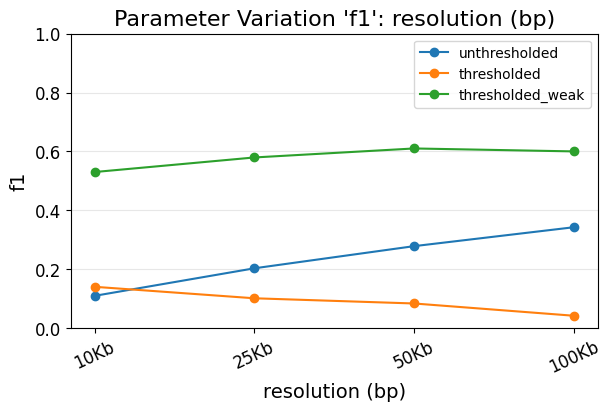

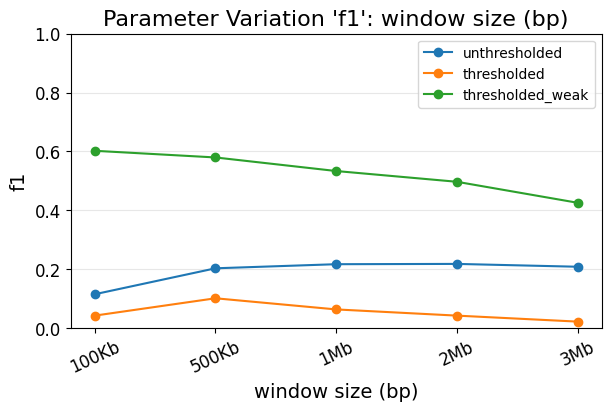

In [11]:

# %%
import matplotlib.pyplot as plt
 
# Headline score (f1): one line per thresholding mode
for cfg in sweep_configs:
    name = cfg["name"]
    x_labels = [cfg["fmt"](v) for v in cfg["values"]]
    f1_by_mode = results[name]
    x_pos = range(len(x_labels))
 
    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    for m in THRESH_MODES:
        ax.plot(x_pos, f1_by_mode[m], marker="o", label=m)
 
    ax.set_xticks(list(x_pos))
    ax.set_xticklabels(x_labels, rotation=25, ha="center", fontsize=10)
 
    ax.set_xlabel(cfg["xlabel"], fontsize=14)
    ax.set_ylabel(f"{score_col}", fontsize=14)
    ax.set_title(
        f"Parameter Variation '{score_col}': {cfg['xlabel']}",
        fontsize=16
    )
 
    ax.tick_params(axis="both", labelsize=12)
 
    ax.set_ylim(0, 1)
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
 
    plt.savefig(f"{analysis_dir}/param_variation_{method}_{name}_{score_col}.png", dpi=300)
 
    plt.show()

In [6]:
# %%
results = {}
for cfg in sweep_configs:
    # per thresholding mode: {f1, precision, recall} lists
    scores_by_mode = {m: {"f1": [], "precision": [], "recall": []} for m in THRESH_MODES}
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        leniency = int(p["resolution"] * 2)
        pools = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            fontanka_base=fontanka_base, leniency=leniency, **p,
        )
        for m in THRESH_MODES:
            pool = pools[m]
            for metric in ("f1", "precision", "recall"):
                scores_by_mode[m][metric].append(pool[metric])
            print(f"[{cfg['name']}={cfg['fmt'](v)} | {m}] "
                  f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
                  f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
    results[cfg["name"]] = scores_by_mode
    print()

[resolution=10kb | unthresholded] TP=69 FP=1176 FN=22 | F1=0.103  P=0.055  R=0.758
[resolution=10kb | thresholded] TP=7 FP=2 FN=84 | F1=0.140  P=0.778  R=0.077
[resolution=10kb | thresholded_weak] TP=60 FP=83 FN=31 | F1=0.513  P=0.420  R=0.659
[resolution=25kb | unthresholded] TP=71 FP=538 FN=20 | F1=0.203  P=0.117  R=0.780
[resolution=25kb | thresholded] TP=5 FP=3 FN=86 | F1=0.101  P=0.625  R=0.055
[resolution=25kb | thresholded_weak] TP=62 FP=61 FN=29 | F1=0.579  P=0.504  R=0.681
[resolution=50kb | unthresholded] TP=78 FP=320 FN=13 | F1=0.319  P=0.196  R=0.857
[resolution=50kb | thresholded] TP=4 FP=1 FN=87 | F1=0.083  P=0.800  R=0.044
[resolution=50kb | thresholded_weak] TP=68 FP=41 FN=23 | F1=0.680  P=0.624  R=0.747
[resolution=100kb | unthresholded] TP=84 FP=193 FN=7 | F1=0.457  P=0.303  R=0.923
[resolution=100kb | thresholded] TP=2 FP=3 FN=89 | F1=0.042  P=0.400  R=0.022
[resolution=100kb | thresholded_weak] TP=69 FP=30 FN=22 | F1=0.726  P=0.697  R=0.758

[window_size=100kb | unt

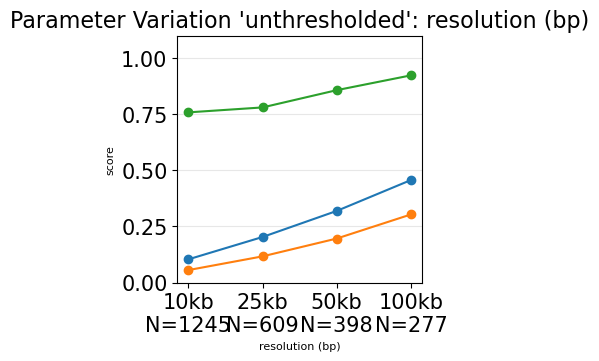

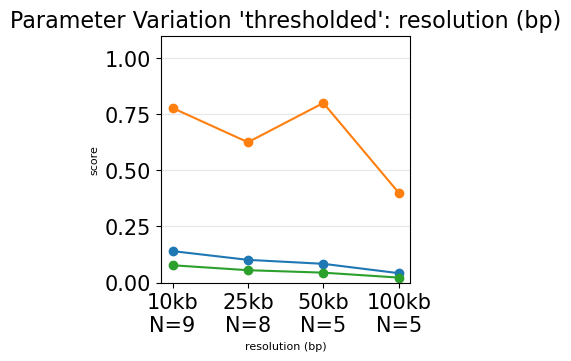

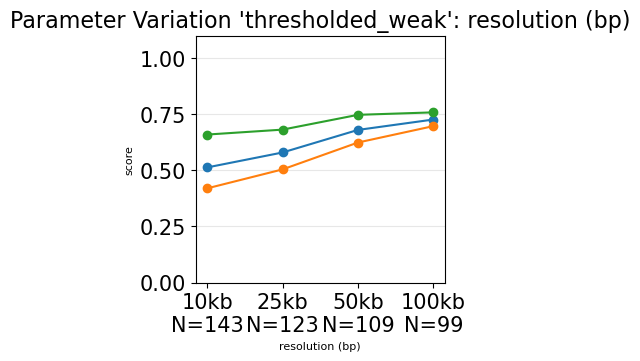

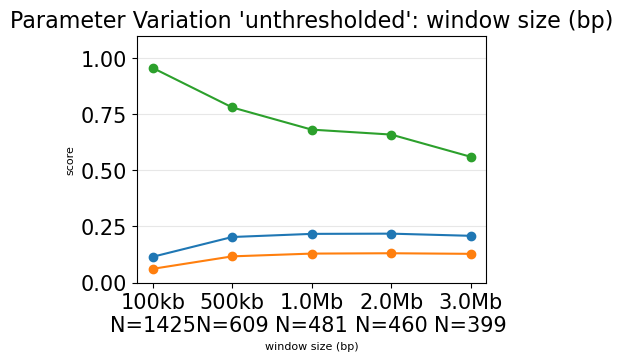

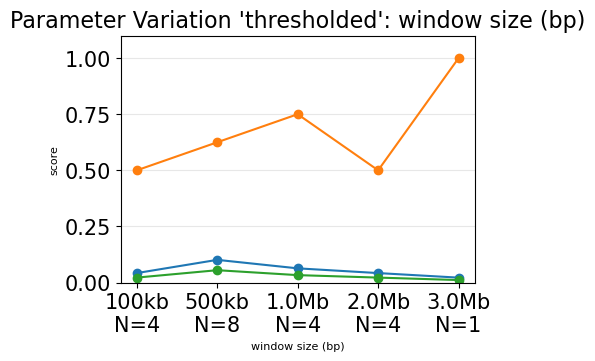

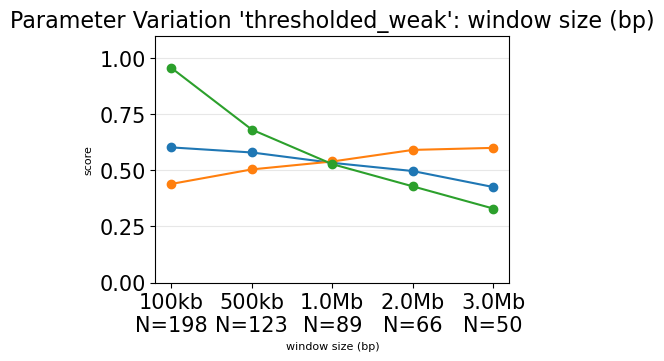

In [15]:
# %%
import matplotlib.pyplot as plt
 
# All metrics: one figure per (parameter, thresholding mode)
for cfg in sweep_configs:
    name = cfg["name"]
    # x_labels = [cfg["fmt"](v) for v in cfg["values"]]
    scores_by_mode = results[name]
    x_pos = range(len(cfg["values"]))
 
    for m in THRESH_MODES:
        scores = scores_by_mode[m]
        x_labels = [f"{cfg['fmt'](v)}\nN={cfg['N_str'][m][i]}"   # + add
                    for i, v in enumerate(cfg["values"])]
        
        if name == "resolution":
            figsize = (3.5, 3.5)
        else:
            figsize = (4.5, 3.5)
         
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        for metric in ("f1", "precision", "recall"):
            ax.plot(x_pos, scores[metric], marker="o", label=metric)
 
        ax.set_xticks(list(x_pos))
        ax.set_xticklabels(x_labels, rotation=0, ha="center", fontsize=15)
 
        ax.set_xlabel(cfg["xlabel"], fontsize=8)
        ax.set_ylabel("score", fontsize=8)
        ax.set_title(
            f"Parameter Variation '{m}': {cfg['xlabel']}",
            fontsize=16
        )
 
        ax.tick_params(axis="both", labelsize=15)
 
        ax.set_ylim(0, 1.1)
        ax.grid(True, axis="y", alpha=0.3)
        # ax.legend(fontsize=20, framealpha=1.0)
 
        plt.savefig(f"{analysis_dir}/param_variation_{method}_{name}_{m}_all.png", dpi=300)
        plt.show()